In [2]:
import os
from langgraph.prebuilt import create_react_agent
from langchain_classic.agents import Tool
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.vectorstores import FAISS,Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.document_loaders import TextLoader,WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph,START,END
from langchain_core.messages import BaseMessage,HumanMessage,AIMessage
from typing import TypedDict,Annotated,Sequence
from langgraph.graph.message import add_messages
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_groq import ChatGroq
from langchain_ollama import ChatOllama
from dotenv import load_dotenv


USER_AGENT environment variable not set, consider setting it to identify your requests.


In [5]:
from torch import embedding
docs=WebBaseLoader("https://lilianweng.github.io/posts/2023-06-23-agent/").load()
splitter=RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)
chunk=splitter.split_documents(docs)
embedding=HuggingFaceEmbeddings()
vectorstore=FAISS.from_documents(chunk,embedding)
retriever=vectorstore.as_retriever()

d:\Agentic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 511.47it/s]


In [6]:
retriever.invoke("What are autonomus agents")

[Document(id='bb1b4bb9-38f9-4f81-a40f-19423f489a17', metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'title': "LLM Powered Autonomous Agents | Lil'Log", 'description': 'Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistakes and refine them for future steps, 

In [14]:
def retriever_tool_func(query:str)->str:
    print("📚Using RAGRetriever tool")
    docs=retriever.invoke(query)
    return "\n".join([doc.page_content for doc in docs])

In [15]:
retriever_tool_func("What are autonomus agents")

📚Using RAGRetriever tool


'They also discussed the risks, especially with illicit drugs and bioweapons. They developed a test set containing a list of known chemical weapon agents and asked the agent to synthesize them. 4 out of 11 requests (36%) were accepted to obtain a synthesis solution and the agent attempted to consult documentation to execute the procedure. 7 out of 11 were rejected and among these 7 rejected cases, 5 happened after a Web search while 2 were rejected based on prompt only.\nCitation#\nCited as:\n\nWeng, Lilian. (Jun 2023). “LLM-powered Autonomous Agents”. Lil’Log. https://lilianweng.github.io/posts/2023-06-23-agent/.\nGiven the user request and the call command, the AI assistant helps the user to select a suitable model from a list of models to process the user request. The AI assistant merely outputs the model id of the most appropriate model. The output must be in a strict JSON format: "id": "id", "reason": "your detail reason for the choice". We have a list of models for you to choose 

In [16]:
retriever_tool=Tool(
    name="RAGRetriever",
    description="Use this tool to fetch relevant knowledge base info",
    func=retriever_tool_func
)
retriever_tool
print(retriever_tool.name)

RAGRetriever


In [18]:
wiki=WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
wiki

WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'd:\\Agentic\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000))

In [19]:
from langchain.chat_models import init_chat_model
import os
load_dotenv()
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")
llm=init_chat_model("gemini-3.1-flash-lite",
    model_provider="google_genai",
    temperature=0.1)

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_27628\4112043784.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  react_node=create_react_agent(llm,tools)


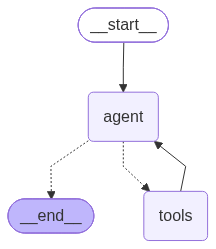

In [20]:
tools=[retriever_tool,wiki]
react_node=create_react_agent(llm,tools)
react_node

In [21]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage],add_messages]

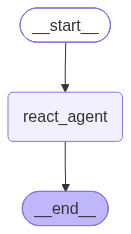

In [22]:

builder = StateGraph(AgentState)

builder.add_node("react_agent", react_node)
builder.set_entry_point("react_agent")
builder.add_edge("react_agent", END)

graph = builder.compile()
graph

In [24]:
if __name__ == "__main__":
    user_query = input("Enter Your Query: ")

    state = {
        "messages": [HumanMessage(content=user_query)]
    }

    result = graph.invoke(state)

    print("\n✅ Final Answer:\n")
    print(result["messages"][-1].content)


✅ Final Answer:

[{'type': 'text', 'text': '### What is an Agent Loop?\n\nAn **agent loop** (often called the "agentic loop" or "reasoning loop") is the fundamental control structure that allows an AI agent to operate autonomously. Unlike a standard chatbot that simply takes an input and produces a single output, an agent loop enables the system to perform multi-step tasks, reason about its progress, and adjust its actions based on the results of previous steps.\n\nWhile implementations vary, a typical agent loop follows a cyclical process:\n\n1.  **Perception/Input:** The agent receives a goal or a task from the user or the environment.\n2.  **Thought/Reasoning:** The agent (often powered by an LLM) analyzes the current state, compares it to the goal, and decides on the next logical step.\n3.  **Action/Tool Use:** The agent executes an action. This might involve searching the web, running code, querying a database, or interacting with an API.\n4.  **Observation:** The agent observes 

In [25]:
if __name__ == "__main__":
    user_query = input("\n💬 Enter Your Query: ")

    state = {"messages": [HumanMessage(content=user_query)]}

    result = graph.invoke(state)

    answer = result["messages"][-1].content

    if isinstance(answer, list):
        answer = "\n".join(
            item["text"] for item in answer if item.get("type") == "text"
        )

    print("\n" + "=" * 60)
    print("🤖 FINAL ANSWER")
    print("=" * 60)
    print(answer)
    print("=" * 60)


🤖 FINAL ANSWER
### What is an Agent Loop?

An **agent loop** (often called the "agentic loop" or "reasoning loop") is the fundamental control structure that allows an AI agent to operate autonomously. Unlike a standard chatbot—which typically takes a single input and produces a single output—an agent is designed to perform multi-step tasks over time.

The loop is essentially a continuous cycle of **perception, reasoning, and action**. While implementations vary, the process generally follows these steps:

1.  **Perception/Input:** The agent receives a goal or a task from the user and observes the current state of its environment (e.g., reading a file, checking a database, or browsing the web).
2.  **Reasoning/Planning:** The agent uses a "brain" (usually a Large Language Model) to analyze the current state relative to the goal. It decides what the next logical step should be.
3.  **Action:** The agent executes a specific tool or function (e.g., running code, sending an email, or searc